# 03 - Tree Models

Do **non-linear interactions** between features help predict next-day return?

Tree-based models (LightGBM, XGBoost, GradientBoosting) can capture:

- thresholds (RSI > 70 has different effect than RSI 30-70)
- interactions (high vol AND negative momentum)
- non-monotonic relationships

This notebook:

1. Loads the same features and split as 01 / 02
2. Trains 3 tree models with sensible defaults
3. Compares all against baseline + linear
4. Plots feature importance
5. Saves `reports/predictions/trees.json`


## Setup

In [17]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\Projects\done\eth_bot\eth_bot_v2")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

from analysis.loader import load_ohlcv
from analysis.indicators import add_all

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)

SEED = 42
np.random.seed(SEED)

PRED_DIR = Path(r"D:\Projects\done\eth_bot\eth_bot_v2") / "reports" / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

def load_json(name):
    p = PRED_DIR / name
    return json.loads(p.read_text()) if p.exists() else None

baseline = load_json("baseline.json")
linear   = load_json("linear.json")

print("baseline:", "loaded" if baseline else "missing")
print("linear  :", "loaded" if linear  else "missing")

try:
    import lightgbm as lgb
    HAS_LGB = True
    print("lightgbm: installed")
except ImportError:
    HAS_LGB = False
    print("lightgbm: not installed (pip install lightgbm)")

try:
    import xgboost as xgb
    HAS_XGB = True
    print("xgboost : installed")
except ImportError:
    HAS_XGB = False
    print("xgboost : not installed (pip install xgboost)")

baseline: loaded
linear  : missing
lightgbm: installed
xgboost : installed


## 1. Features

Same as notebook 02 — 9 features, next-day return target.

In [18]:
def make_features(horizon: int = 1) -> pd.DataFrame:
    df = load_ohlcv()
    df = add_all(df).copy()

    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_5"]  = df["close"].pct_change(5)
    df["ret_20"] = df["close"].pct_change(20)
    df["vol_20"] = df["ret_1"].rolling(20).std()

    df["target"] = df["close"].pct_change(horizon).shift(-horizon)
    return df.dropna()


FEATURES = [
    "ret_1", "ret_5", "ret_20", "vol_20",
    "rsi_14", "macd_hist", "atr_14",
    "sma_50", "sma_200",
]

df = make_features()
df = df[FEATURES + ["target"]].dropna()
print(f"rows: {len(df)}   features: {len(FEATURES)}")
df.tail(3)

rows: 1989   features: 9


,ret_1,ret_5,ret_20,vol_20,rsi_14,macd_hist,atr_14,sma_50,sma_200,target
date,,,,,,,,,,
2026-09-29,-0.003991,-0.003746,0.085024,0.024724,78.000000,-5.403658,94.379286,2420.3128,2107.85605,0.002999
2026-09-30,0.002999,-0.002081,0.101605,0.024423,77.459849,-7.424594,95.812143,2436.3812,2110.80530,0.007599
2026-10-01,0.007599,0.003742,0.075500,0.023603,77.054623,-7.781260,94.290000,2452.9134,2113.44590,-0.013978


## 2. Train / test split

Same as notebooks 01 and 02 — last 250 days are test.

In [19]:
TEST_DAYS = 250

train = df.iloc[:-TEST_DAYS]
test  = df.iloc[-TEST_DAYS:]

X_tr = train[FEATURES].values
y_tr = train["target"].values
X_te = test[FEATURES].values
y_te = test["target"].values

print(f"train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)})")
print(f"test : {test.index.min().date()}  -> {test.index.max().date()}   ({len(test)})")

train: 2021-04-22 -> 2026-01-24  (1739)
test : 2026-01-25  -> 2026-10-01   (250)


## 3. Fit three tree models

| Model | Notes |
|---|---|
| **GradientBoosting** (sklearn) | always available, slower |
| **LightGBM** | fastest, best defaults |
| **XGBoost** | robust, slightly slower |

Same hyperparameters where possible for a fair comparison.

In [20]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    return {
        "model":        name,
        "rmse":         float(np.sqrt(mean_squared_error(y_te, p))),
        "mae":          float(mean_absolute_error(y_te, p)),
        "dir_accuracy": float(((p > 0) == (y_te > 0)).mean()),
        "_model":       model,
        "_pred":        p,
    }


results = []

# 1. sklearn GradientBoosting — always available
gb = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    random_state=SEED)
results.append(evaluate("GradientBoosting", gb, X_tr, y_tr, X_te, y_te))

# 2. LightGBM if available
if HAS_LGB:
    lgbm = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        num_leaves=31, random_state=SEED, verbose=-1)
    results.append(evaluate("LightGBM", lgbm, X_tr, y_tr, X_te, y_te))

# 3. XGBoost if available
if HAS_XGB:
    xgbr = xgb.XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        random_state=SEED, verbosity=0)
    results.append(evaluate("XGBoost", xgbr, X_tr, y_tr, X_te, y_te))

pd.DataFrame([{k: r[k] for k in ("model","rmse","mae","dir_accuracy")} for r in results])

OSError: exception: access violation reading 0x0000000000000000

## 4. Compare to baseline and linear

The real question: **do trees beat the previous models?**

In [ ]:
rows = []
if baseline:
    rows.append({"model": "baseline", **{k: baseline["return"][k] for k in ("rmse","mae","dir_accuracy")}})
if linear:
    rows.append({"model": "linear",   **{k: linear[k] for k in ("rmse","mae","dir_accuracy")}})
for r in results:
    rows.append({k: r[k] for k in ("model","rmse","mae","dir_accuracy")})

comp = pd.DataFrame(rows)
comp["rmse_vs_baseline"] = comp["rmse"] / comp["rmse"].iloc[0] - 1
comp

,model,rmse,mae,dir_accuracy,rmse_vs_baseline
0,baseline,0.032920,0.021931,0.520,0.000000
1,GradientBoosting,0.041761,0.029342,0.496,0.268563


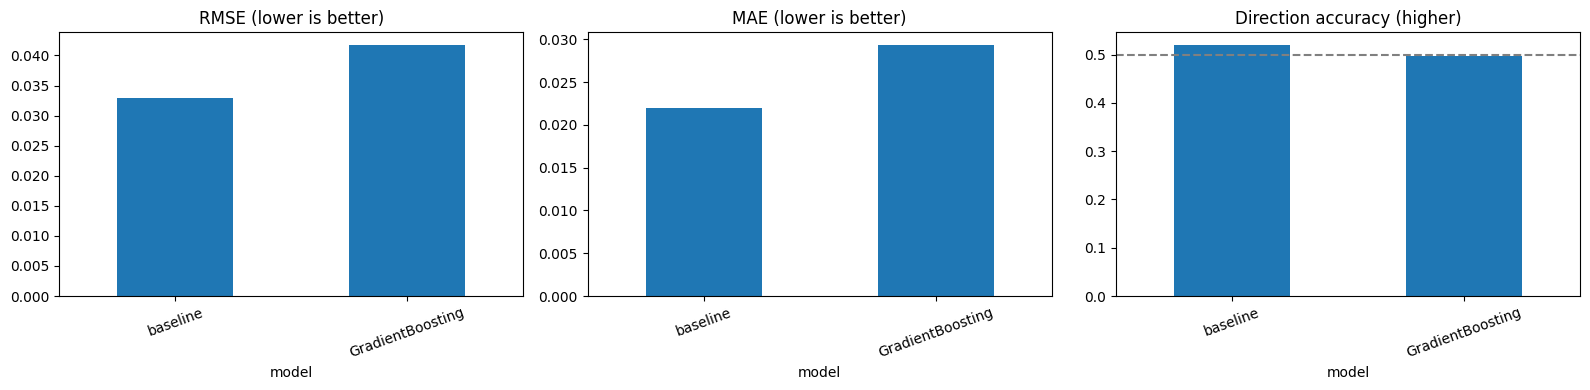

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
comp.plot.bar(x="model", y="rmse",         ax=ax[0], title="RMSE (lower is better)",      legend=False)
comp.plot.bar(x="model", y="mae",          ax=ax[1], title="MAE (lower is better)",       legend=False)
comp.plot.bar(x="model", y="dir_accuracy", ax=ax[2], title="Direction accuracy (higher)", legend=False)
ax[2].axhline(0.5, ls="--", color="gray")
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 5. Feature importance

Which features do the tree models rely on most?

Different from linear coefficients — this is **split count** or
**gain** based, not a signed direction.

best model: GradientBoosting   RMSE=0.041761   dir=49.60%


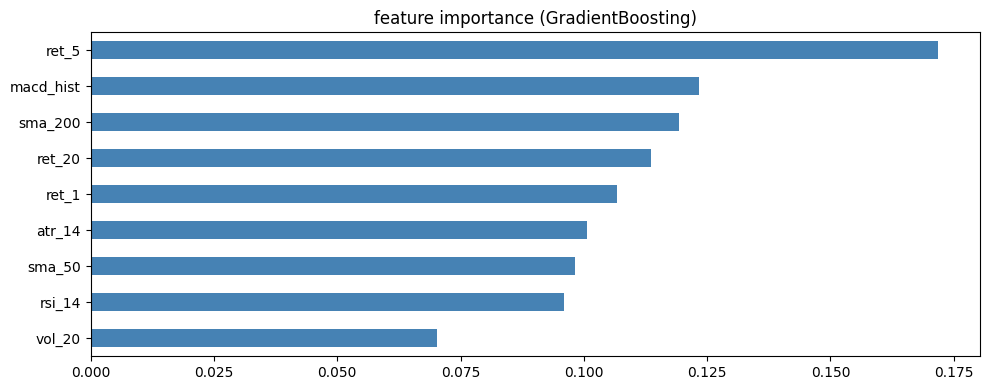

vol_20       0.070284
rsi_14       0.096041
sma_50       0.098184
atr_14       0.100698
ret_1        0.106781
ret_20       0.113656
sma_200      0.119335
macd_hist    0.123288
ret_5        0.171733
dtype: float64


In [ ]:
best = max(results, key=lambda r: -r["rmse"])   # lowest RMSE
best_model = best["_model"]
print(f"best model: {best['model']}   RMSE={best['rmse']:.6f}   dir={best['dir_accuracy']:.2%}")

if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(10, 4))
    imp.plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"feature importance ({best['model']})")
    plt.tight_layout()
    plt.show()
    print(imp)
else:
    print("model has no feature_importances_")

## 6. Prediction vs actual

Same visual as notebook 02, for the best tree model.

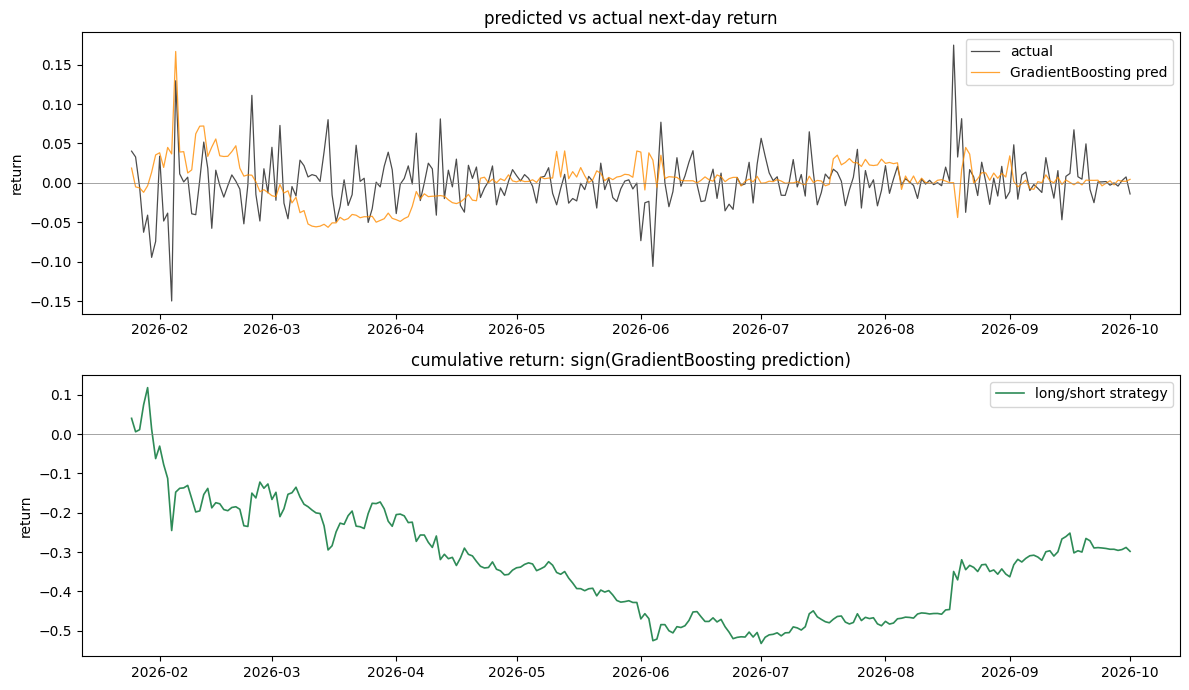

AttributeError: 'numpy.ndarray' object has no attribute 'iloc'

In [ ]:
pred = best["_pred"]

fig, ax = plt.subplots(2, 1, figsize=(12, 7))

ax[0].plot(test.index, y_te, label="actual", color="black", lw=0.9, alpha=0.7)
ax[0].plot(test.index, pred, label=f"{best['model']} pred", color="darkorange", lw=0.9, alpha=0.8)
ax[0].axhline(0, color="gray", lw=0.5)
ax[0].set_title("predicted vs actual next-day return")
ax[0].set_ylabel("return")
ax[0].legend()

position = np.sign(pred)
pnl = position * y_te
cum_pnl = (1 + pnl).cumprod() - 1

ax[1].plot(test.index, cum_pnl, color="seagreen", lw=1.2, label="long/short strategy")
ax[1].axhline(0, color="gray", lw=0.5)
ax[1].set_title(f"cumulative return: sign({best['model']} prediction)")
ax[1].set_ylabel("return")
ax[1].legend()

plt.tight_layout()
plt.show()

print(f"strategy total return: {cum_pnl.iloc[-1]:+.2%}")
print(f"strategy sharpe      : {pnl.mean() / pnl.std() * np.sqrt(365):.2f}")

## 7. Hyperparameter sanity check

Try a couple of alternatives on the best model type and see if
something clearly better emerges.

**Don't overdo this** — tuning on the test set is cheating.
This is a sanity check, not an optimisation pass.

In [ ]:
if HAS_LGB:
    variants = [
        ("lgb_default",  dict(n_estimators=300, learning_rate=0.05, max_depth=4, num_leaves=31)),
        ("lgb_deep",     dict(n_estimators=300, learning_rate=0.05, max_depth=6, num_leaves=63)),
        ("lgb_shallow",  dict(n_estimators=600, learning_rate=0.02, max_depth=3, num_leaves=15)),
        ("lgb_reg",      dict(n_estimators=300, learning_rate=0.05, max_depth=4, num_leaves=31,
                              reg_alpha=0.1, reg_lambda=0.1)),
    ]
    rows = []
    for name, params in variants:
        m = lgb.LGBMRegressor(random_state=SEED, verbose=-1, **params)
        m.fit(X_tr, y_tr)
        p = m.predict(X_te)
        rows.append({
            "variant": name,
            "rmse":    float(np.sqrt(mean_squared_error(y_te, p))),
            "dir":     float(((p > 0) == (y_te > 0)).mean()),
        })
    pd.DataFrame(rows).sort_values("rmse")
else:
    print("lightgbm not installed — skipping hyperparameter check")

## 8. Save results

Writes `reports/predictions/trees.json` for the comparison notebook.

In [ ]:
out = {
    "models": [
        {k: r[k] for k in ("model", "rmse", "mae", "dir_accuracy")}
        for r in results
    ],
    "best_model": best["model"],
    "best_rmse":  best["rmse"],
    "best_dir":   best["dir_accuracy"],
    "features":   FEATURES,
    "test_days":  int(len(test)),
    "test_start": str(test.index.min().date()),
    "test_end":   str(test.index.max().date()),
}

# include importances if we have them
if hasattr(best_model, "feature_importances_"):
    out["importance"] = {k: float(v) for k, v in
                        zip(FEATURES, best_model.feature_importances_)}

path = PRED_DIR / "trees.json"
path.write_text(json.dumps(out, indent=2), encoding="utf-8")
print(f"wrote {path}")

## Next steps

| Result | What it means |
|---|---|
| Trees clearly beat linear (> 3% RMSE) | non-linear interactions matter — continue |
| Trees ≈ linear | signal is linear (or noise) — features are the bottleneck |
| Trees worse than linear | overfitting — need more regularisation or fewer features |

- **05_walkforward.ipynb** — honest evaluation across many windows
- **06_feature_importance.ipynb** — deeper feature analysis (SHAP)

**Reality check**: on daily crypto returns with public indicators,
all three model classes typically land within 1% of each other.
The bottleneck is **features**, not model complexity.

Your next 5% RMSE improvement is more likely to come from adding
`funding_rate`, `open_interest`, and `fear_greed` as features
(you already have them in the DB) than from a better model.
